# Experiment 5 — AI-Based E-Commerce Cart Optimization System

**Aim:** To design and implement an AI-Based E-Commerce Cart Optimization System that understands natural-language shopping requirements, decomposes them into structured constraints, and generates an optimized product cart that satisfies the user's budget, quality and product-specific requirements while providing the best possible value.

**Theory (summary):** The system accepts a natural-language shopping query and performs **query decomposition** (categories, quantity, budget, minimum rating, brands, product-specific constraints, objective) into a structured JSON plan. It then runs **Search → Filter → Compare → Optimize**. A weighted **value score** (rating 60 % + price 40 %) is used to rank the generated carts by total price, average rating, savings and value score. Finally an **AI explanation agent** explains why the cart was selected and what trade-offs exist.

**How to run:** `Runtime → Run all`. For the LLM steps add a free Groq key in Colab *Secrets* (🔑 icon in the left bar) under the name `GROQ_API_KEY` and enable notebook access. If no key is found, the notebook automatically uses a built-in rule-based fallback so every cell still runs.

## 1. Setup

In [ ]:
!pip install -q langchain-groq

In [ ]:
import os
import re
import json
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 2. LLM configuration
The notebook uses a LangChain chat model (`llm.invoke(prompt)` → `response.content`). To use another provider (OpenAI, Gemini, ...) just replace the `ChatGroq(...)` line with the matching LangChain chat model.

In [ ]:
def load_llm():
    """Return a LangChain chat model, or None if no API key is available."""
    key = os.environ.get("GROQ_API_KEY")
    if not key:
        try:
            from google.colab import userdata
            key = userdata.get("GROQ_API_KEY")
        except Exception:
            key = None
    if not key:
        return None
    try:
        from langchain_groq import ChatGroq
        return ChatGroq(
            model="llama-3.3-70b-versatile",
            temperature=0,
            groq_api_key=key
        )
    except Exception as e:
        print("Could not initialise the Groq LLM:", e)
        return None


llm = load_llm()
print("LLM mode:", "Groq (llama-3.3-70b-versatile)" if llm is not None
      else "offline rule-based fallback (no GROQ_API_KEY found)")

LLM mode: offline rule-based fallback (no GROQ_API_KEY found)


## 3. Product dataset
The first 17 rows are the catalogue from the experiment. A few extra rows (Screen Protector, Mobile Stand, Car Mount, Wireless Charger) complete the 8 categories so that the *Average Price by Category* chart can be produced. A `wireless` column is included because `filter_products()` supports a wireless filter.

In [ ]:
columns = ["product_id", "product_name", "category", "brand", "price",
           "rating", "wattage", "capacity", "warranty", "wireless"]

rows = [
    # ---- Chargers
    ("CH01", "Portronics Adapto 20W Charger",      "Charger",      "Portronics",  699, 4.3, 20.0,     0, 12, "No"),
    ("CH02", "Spigen ArcStation 30W Charger",      "Charger",      "Spigen",     1499, 4.6, 30.0,     0, 12, "No"),
    ("CH03", "Ambrane 33W Fast Charger",           "Charger",      "Ambrane",     999, 4.4, 33.0,     0, 12, "No"),
    ("CH04", "Stuffcool 65W GaN Charger",          "Charger",      "Stuffcool",  2299, 4.7, 65.0,     0, 18, "No"),
    # ---- Power banks
    ("PB01", "Ambrane 10000mAh Power Bank",        "Power Bank",   "Ambrane",     999, 4.3, 22.5, 10000, 12, "No"),
    ("PB02", "Portronics 20000mAh Power Bank",     "Power Bank",   "Portronics", 1599, 4.4, 22.5, 20000, 12, "No"),
    ("PB03", "URBN 10000mAh Mini Power Bank",      "Power Bank",   "URBN",       1299, 4.5, 22.5, 10000, 12, "No"),
    ("PB04", "Spigen 10000mAh Wireless Power Bank","Power Bank",   "Spigen",     2499, 4.6, 20.0, 10000, 12, "Yes"),
    # ---- USB cables
    ("CB01", "Portronics USB-C 60W Cable",         "USB Cable",    "Portronics",  399, 4.2, 60.0,     0,  6, "No"),
    ("CB02", "Anker PowerLine USB-C Cable",        "USB Cable",    "Anker",       799, 4.7, 100.0,    0, 18, "No"),
    ("CB03", "Ambrane USB-C 65W Cable",            "USB Cable",    "Ambrane",     499, 4.4, 65.0,     0, 12, "No"),
    ("CB04", "Spigen USB-C 100W Cable",            "USB Cable",    "Spigen",      899, 4.6, 100.0,    0, 24, "No"),
    # ---- Phone cases
    ("PC01", "Spigen Rugged Armor Case",           "Phone Case",   "Spigen",     1299, 4.7, 0.0,      0, 12, "No"),
    ("PC02", "Ringke Fusion Case",                 "Phone Case",   "Ringke",      999, 4.5, 0.0,      0,  6, "No"),
    ("PC03", "DailyObjects Protective Case",       "Phone Case",   "DailyObjects",799, 4.2, 0.0,      0,  6, "No"),
    ("PC04", "ESR MagSafe Compatible Case",        "Phone Case",   "ESR",        1499, 4.6, 0.0,      0, 12, "No"),
    # ---- Screen protectors
    ("SP01", "Spigen Tempered Glass",              "Screen Protector", "Spigen",   699, 4.6, 0.0,     0,  6, "No"),
    ("SP02", "ESR Tempered Glass",                 "Screen Protector", "ESR",      499, 4.4, 0.0,     0,  6, "No"),
    ("SP03", "Ambrane Tempered Glass",             "Screen Protector", "Ambrane",  499, 4.1, 0.0,     0,  6, "No"),
    # ---- Mobile stands
    ("MS01", "Portronics Adjustable Mobile Stand", "Mobile Stand", "Portronics",  799, 4.3, 0.0,     0, 12, "No"),
    ("MS02", "Ambrane Foldable Mobile Stand",      "Mobile Stand", "Ambrane",     699, 4.1, 0.0,     0,  6, "No"),
    ("MS03", "Spigen Desk Mobile Stand",           "Mobile Stand", "Spigen",      799, 4.4, 0.0,     0, 12, "No"),
    # ---- Car mounts
    ("CM01", "Spigen Car Mount",                   "Car Mount",    "Spigen",     1299, 4.6, 0.0,     0, 12, "No"),
    ("CM02", "Ambrane Car Mount",                  "Car Mount",    "Ambrane",    1199, 4.3, 0.0,     0,  6, "No"),
    ("CM03", "Portronics Car Mount",               "Car Mount",    "Portronics", 1199, 4.4, 0.0,     0, 12, "No"),
    # ---- Wireless chargers
    ("WC01", "Spigen MagSafe Wireless Charger",    "Wireless Charger", "Spigen",  1499, 4.6, 15.0,    0, 12, "Yes"),
    ("WC02", "Ambrane Wireless Charger",           "Wireless Charger", "Ambrane", 1099, 4.2, 10.0,    0,  6, "Yes"),
    ("WC03", "Portronics Wireless Charger",        "Wireless Charger", "Portronics",1299,4.4, 15.0,   0, 12, "Yes"),
]

df = pd.DataFrame(rows, columns=columns)
df["wattage"] = df["wattage"].astype(float)

KNOWN_CATEGORIES = ["Charger", "Power Bank", "USB Cable", "Phone Case",
                    "Screen Protector", "Mobile Stand", "Car Mount", "Wireless Charger"]
CATEGORY_LOOKUP = {c.lower(): c for c in KNOWN_CATEGORIES}

display(df)

,product_id,product_name,category,brand,price,rating,wattage,capacity,warranty,wireless
0,CH01,Portronics Adapto 20W Charger,Charger,Portronics,699,4.3,20.0,0,12,No
1,CH02,Spigen ArcStation 30W Charger,Charger,Spigen,1499,4.6,30.0,0,12,No
2,CH03,Ambrane 33W Fast Charger,Charger,Ambrane,999,4.4,33.0,0,12,No
3,CH04,Stuffcool 65W GaN Charger,Charger,Stuffcool,2299,4.7,65.0,0,18,No
4,PB01,Ambrane 10000mAh Power Bank,Power Bank,Ambrane,999,4.3,22.5,10000,12,No
5,PB02,Portronics 20000mAh Power Bank,Power Bank,Portronics,1599,4.4,22.5,20000,12,No
6,PB03,URBN 10000mAh Mini Power Bank,Power Bank,URBN,1299,4.5,22.5,10000,12,No
7,PB04,Spigen 10000mAh Wireless Power Bank,Power Bank,Spigen,2499,4.6,20.0,10000,12,Yes
8,CB01,Portronics USB-C 60W Cable,USB Cable,Portronics,399,4.2,60.0,0,6,No
9,CB02,Anker PowerLine USB-C Cable,USB Cable,Anker,799,4.7,100.0,0,18,No


## 4. Query Decomposition Agent
The LLM converts the natural-language query into a structured JSON plan. A rule-based decomposer is used as a fallback (no API key, or invalid LLM output), and `normalise_plan()` cleans the JSON so later stages never break.

In [ ]:
NUM_WORDS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5}

CATEGORY_PATTERNS = [
    ("Wireless Charger", r"wireless\s+(?:charger|charging\s+pad)s?"),
    ("Power Bank",       r"power\s*banks?"),
    ("USB Cable",        r"usb(?:-|\s)?c?\s*cables?|charging\s+cables?|\bcables?\b"),
    ("Screen Protector", r"screen\s+protectors?|tempered\s+glass"),
    ("Phone Case",       r"(?:phone|mobile)\s+cases?|\bcases?\b|\bcovers?\b"),
    ("Mobile Stand",     r"(?:mobile|phone)\s+stands?|\bstands?\b"),
    ("Car Mount",        r"car\s+(?:mount|holder)s?|phone\s+holders?"),
    ("Charger",          r"\bchargers?\b"),
]


def to_number(value):
    """Convert 5000 / '5,000' / '₹5000' / None into an int/float (or None)."""
    if value is None:
        return None
    try:
        number = float(str(value).replace(",", "").replace("₹", "").strip())
    except ValueError:
        return None
    return int(number) if number.is_integer() else number


def rule_based_decompose(user_query):
    """Regex based fallback decomposer (used when no LLM is available)."""
    ql = " ".join(user_query.split()).lower()
    work = ql
    categories, quantities, positions = [], {}, {}

    for cat, pattern in CATEGORY_PATTERNS:
        m = re.search(pattern, work)
        if not m:
            continue
        categories.append(cat)
        positions[cat] = m.start()
        before = work[max(0, m.start() - 30):m.start()]
        qm = re.search(r"\b(\d{1,2}|one|two|three|four|five)\s+(?:[\w\-]+\s+){0,2}$", before)
        if qm:
            g = qm.group(1)
            quantities[cat] = NUM_WORDS[g] if g in NUM_WORDS else int(g)
        else:
            quantities[cat] = 1
        work = work[:m.start()] + " " * (m.end() - m.start()) + work[m.end():]

    categories.sort(key=lambda c: positions[c])   # keep the order used in the query

    # budget
    bm = (re.search(r"(?:₹|rs\.?|inr)\s*([\d,]+(?:\.\d+)?)", ql)
          or re.search(r"budget[^\d]{0,30}([\d,]+(?:\.\d+)?)", ql))
    budget = to_number(bm.group(1)) if bm else None

    # minimum rating
    rm = re.search(r"(?:rating|ratings|rated)\D{0,30}?(\d(?:\.\d+)?)", ql)
    min_rating = float(rm.group(1)) if rm else None

    # brands (only real brand names present in the catalogue)
    brands = [b for b in sorted(df["brand"].unique()) if b.lower() in ql]

    # product-specific constraints
    specific = {}
    cm = re.search(r"(\d[\d,]*)\s*mah", ql)
    if cm and "Power Bank" in categories:
        specific["Power Bank"] = cm.group(1).replace(",", "") + "mAh"
    wm = re.search(r"(\d+(?:\.\d+)?)\s*w\b", ql)
    if wm and "Charger" in categories:
        specific["Charger"] = wm.group(1) + "W"
    if re.search(r"\bfast\b", ql) and "Charger" in categories and "Charger" not in specific:
        specific["Charger"] = "fast charging"

    # objective
    if re.search(r"minimi[sz]e|cheapest|lowest|least cost|save money", ql):
        objective = "minimize total cost while maintaining good product quality"
    elif re.search(r"best quality|highest rat|best rated", ql):
        objective = "maximize product quality within budget"
    else:
        objective = "maximize overall value (rating and price)"

    return {
        "categories": categories,
        "quantities": quantities,
        "budget": budget,
        "min_rating": min_rating,
        "brands": brands,
        "constraints": {"product_specific": specific} if specific else {},
        "optimization_objective": objective,
        "subtasks": ["Search", "Filter", "Compare", "Optimize"],
    }


def extract_json(text):
    text = text.replace("```json", "").replace("```", "").strip()
    try:
        return json.loads(text)
    except Exception:
        m = re.search(r"\{.*\}", text, re.DOTALL)
        if m:
            return json.loads(m.group(0))
        raise


def normalise_plan(plan):
    """Make sure the plan has every key, canonical category names and clean types."""
    plan = dict(plan)

    categories = []
    for c in plan.get("categories") or []:
        canon = CATEGORY_LOOKUP.get(str(c).strip().lower())
        if canon and canon not in categories:
            categories.append(canon)

    quantities = {}
    raw_q = plan.get("quantities")
    for k, v in (raw_q.items() if isinstance(raw_q, dict) else []):
        canon = CATEGORY_LOOKUP.get(str(k).strip().lower())
        if canon:
            try:
                quantities[canon] = max(1, int(v))
            except (TypeError, ValueError):
                quantities[canon] = 1
    for c in categories:
        quantities.setdefault(c, 1)

    brands = plan.get("brands")
    brands = [str(b) for b in brands] if isinstance(brands, list) else []

    constraints = plan.get("constraints")
    constraints = constraints if isinstance(constraints, dict) else {}

    subtasks = plan.get("subtasks")
    if not isinstance(subtasks, list) or not subtasks:
        subtasks = ["Search", "Filter", "Compare", "Optimize"]

    return {
        "categories": categories,
        "quantities": quantities,
        "budget": to_number(plan.get("budget")),
        "min_rating": to_number(plan.get("min_rating")),
        "brands": brands,
        "constraints": constraints,
        "optimization_objective": plan.get("optimization_objective") or "Minimize total cost",
        "subtasks": subtasks,
    }

In [ ]:
def decompose_query(user_query):

    prompt = f"""
You are a Query Decomposition Agent for a Mobile Accessories
E-Commerce Cart Optimization System.

User Query:
{user_query}

Identify the following:

1. Required product categories
2. Quantity required for each category
3. Maximum total budget
4. Minimum rating
5. Preferred brands (only real brand names written by the user, otherwise [])
6. Product-specific constraints
7. Optimization objective

Available categories:
Charger, Power Bank, USB Cable, Phone Case,
Screen Protector, Mobile Stand, Car Mount, Wireless Charger

Write product-specific constraints per category, for example:
"constraints": {{"product_specific": {{"Power Bank": "20000mAh", "Charger": "fast charging"}}}}

Return ONLY valid JSON in this format:

{{
    "categories": [],
    "quantities": {{}},
    "budget": null,
    "min_rating": null,
    "brands": [],
    "constraints": {{}},
    "optimization_objective": "",
    "subtasks": []
}}

Subtasks must contain:
Search, Filter, Compare, Optimize.
"""

    result = None

    if llm is not None:
        try:
            response = llm.invoke(prompt)
            result = extract_json(response.content.strip())
        except Exception as e:
            print("LLM decomposition failed, using rule-based fallback:", e)

    if result is None:
        result = rule_based_decompose(user_query)

    return normalise_plan(result)

In [ ]:
user_query = """
I need a fast charger, a 20000mAh power bank and a USB-C cable.
My total budget is ₹5000.
I want products rated above 4.3.
Prefer reliable brands and minimize the total cost while maintaining good quality.
"""

plan = decompose_query(user_query)

print(json.dumps(plan, indent=4))

{
    "categories": [
        "Charger",
        "Power Bank",
        "USB Cable"
    ],
    "quantities": {
        "Power Bank": 1,
        "USB Cable": 1,
        "Charger": 1
    },
    "budget": 5000,
    "min_rating": 4.3,
    "brands": [],
    "constraints": {
        "product_specific": {
            "Power Bank": "20000mAh",
            "Charger": "fast charging"
        }
    },
    "optimization_objective": "minimize total cost while maintaining good product quality",
    "subtasks": [
        "Search",
        "Filter",
        "Compare",
        "Optimize"
    ]
}


## 5. Search → Filter → Compare
* `search_products` — all products of a category, best rated first.
* `filter_products` — removes products violating price, rating, wattage, capacity, warranty, brand or wireless constraints.
* `compare_products` — value score = **0.6 × rating score + 0.4 × price score**, where `rating_score = rating / 5` and `price_score = cheapest price / price`.

In [ ]:
def search_products(category):

    results = df[
        df["category"].str.lower() == str(category).lower()
    ].copy()

    results = results.sort_values(
        by=["rating", "price"],
        ascending=[False, True]
    )

    return results


def filter_products(
    products,
    max_price=None,
    min_rating=None,
    min_wattage=None,
    min_capacity=None,
    min_warranty=None,
    brand=None,
    wireless=None
):

    result = products.copy()

    if max_price is not None:
        result = result[result["price"] <= max_price]

    if min_rating is not None:
        result = result[result["rating"] >= min_rating]

    if min_wattage is not None:
        result = result[result["wattage"] >= min_wattage]

    if min_capacity is not None:
        result = result[result["capacity"] >= min_capacity]

    if min_warranty is not None:
        result = result[result["warranty"] >= min_warranty]

    if brand:
        result = result[
            result["brand"].str.lower().isin(
                [b.lower() for b in brand]
            )
        ]

    if wireless is not None:
        result = result[
            result["wireless"].str.lower() == wireless.lower()
        ]

    return result


def compare_products(products):

    result = products.copy()

    if len(result) == 0:
        return result

    min_price = result["price"].min()

    result["rating_score"] = result["rating"] / 5
    result["price_score"] = min_price / result["price"]

    result["value_score"] = (
        0.6 * result["rating_score"]
        + 0.4 * result["price_score"]
    )

    result = result.sort_values(
        by="value_score",
        ascending=False
    )

    return result

### Constraint parser and the Search → Filter → Compare pipeline
`parse_constraints()` turns the LLM's product-specific constraints (e.g. `"Power Bank": "20000mAh"`) into filter arguments, so the 20000 mAh requirement is really enforced. Brand names that are not real brands in the catalogue (such as the word *reliable*) are treated as a soft preference and ignored.

In [ ]:
# True  -> product-specific constraints (e.g. 20000mAh) are strictly enforced
# False -> only budget / rating / brand filters are used
ENFORCE_PRODUCT_CONSTRAINTS = True


def parse_constraints(constraints):
    """Convert LLM product-specific constraints into filter_products() keyword arguments per category."""
    found = {}

    def add(cat, text):
        t = text.lower()
        kw = found.setdefault(cat, {})

        m = re.search(r"(\d[\d,]*)\s*mah", t) or re.search(r"capacity\D*(\d[\d,]*)", t)
        if m:
            kw["min_capacity"] = int(m.group(1).replace(",", ""))

        m = re.search(r"(\d+(?:\.\d+)?)\s*w\b", t) or re.search(r"watt(?:age)?\D*(\d+(?:\.\d+)?)", t)
        if m:
            kw["min_wattage"] = float(m.group(1))

        m = re.search(r"warranty\D*(\d+)", t) or re.search(r"(\d+)\s*months?", t)
        if m:
            kw["min_warranty"] = int(m.group(1))

        if "wireless" in t and cat != "Wireless Charger":
            kw["wireless"] = "yes"

        if "fast" in t and cat == "Charger" and "min_wattage" not in kw:
            kw["min_wattage"] = 18.0

    def walk(node, cat=None, path=""):
        if isinstance(node, dict):
            for k, v in node.items():
                key = str(k).strip().lower().replace("_", " ")
                walk(v, CATEGORY_LOOKUP.get(key, cat), path + " " + str(k))
        elif isinstance(node, (list, tuple)):
            for v in node:
                walk(v, cat, path)
        else:
            if cat and node not in (None, False, ""):
                add(cat, f"{path} {node}")

    walk(constraints or {})
    return {c: kw for c, kw in found.items() if kw}


def execute_search_and_filter(plan, top_n=5):
    """Run Search -> Filter -> Compare for every required category.
    Returns {category: [product dicts sorted by value score]}."""
    budget = plan.get("budget")
    min_rating = plan.get("min_rating")

    known_brands = {b.lower() for b in df["brand"].unique()}
    brands = [b for b in plan.get("brands", []) if str(b).lower() in known_brands]

    specific = parse_constraints(plan.get("constraints")) if ENFORCE_PRODUCT_CONSTRAINTS else {}

    candidate_groups = {}

    for category in plan.get("categories", []):
        category = CATEGORY_LOOKUP.get(str(category).lower(), category)

        products = search_products(category)                      # SEARCH
        if products.empty:
            print(f"Warning: no products found for category '{category}'.")
            candidate_groups[category] = []
            continue

        kwargs = dict(max_price=budget, min_rating=min_rating, brand=brands or None)
        kwargs.update(specific.get(category, {}))

        filtered = filter_products(products, **kwargs)            # FILTER

        if filtered.empty:                                        # relax soft constraints
            print(f"Warning: no '{category}' satisfies all constraints {kwargs}; "
                  f"relaxing brand / product-specific constraints.")
            filtered = filter_products(products, max_price=budget, min_rating=min_rating)

        compared = compare_products(filtered).head(top_n)         # COMPARE
        candidate_groups[category] = compared.to_dict("records")

    return candidate_groups

## 6. Cart Optimization
Every combination of one product per category is generated, carts above the budget are dropped, and the remaining carts are ranked by **cart value score = 100 × (0.6 × average rating / 5 + 0.4 × cheapest possible cart price / cart price)**.
`Savings` = price of the most expensive candidate combination − price of the cart.

In [ ]:
CART_COLUMNS = ["products", "total_price", "average_rating", "savings", "value_score"]


def optimize_cart(candidate_groups, budget, quantities=None):
    quantities = quantities or {}
    categories = list(candidate_groups.keys())

    if not categories or any(len(candidate_groups[c]) == 0 for c in categories):
        return pd.DataFrame(columns=CART_COLUMNS)

    qty = {c: max(1, int(quantities.get(c, 1))) for c in categories}

    min_total = sum(min(p["price"] for p in candidate_groups[c]) * qty[c] for c in categories)
    max_total = sum(max(p["price"] for p in candidate_groups[c]) * qty[c] for c in categories)

    rows = []
    for combo in itertools.product(*[candidate_groups[c] for c in categories]):
        items = [p for c, p in zip(categories, combo) for _ in range(qty[c])]

        total_price = int(sum(p["price"] for p in items))
        if total_price > budget:
            continue

        avg_rating = float(np.mean([p["rating"] for p in items]))
        savings = float(max_total - total_price)

        rating_score = avg_rating / 5
        price_score = min_total / total_price
        value_score = 100 * (0.6 * rating_score + 0.4 * price_score)

        rows.append({
            "products": items,
            "total_price": total_price,
            "average_rating": avg_rating,
            "savings": savings,
            "value_score": value_score,
        })

    if not rows:
        return pd.DataFrame(columns=CART_COLUMNS)

    carts = pd.DataFrame(rows, columns=CART_COLUMNS)
    carts = carts.sort_values(by=["value_score", "total_price"], ascending=[False, True])
    return carts.reset_index(drop=True)

## 7. Cart Optimization Agent (full pipeline)

In [ ]:
def cart_optimization_agent(user_query):

    print("=" * 70)
    print("AI MOBILE ACCESSORIES CART OPTIMIZATION AGENT")
    print("=" * 70)

    # STEP 1
    print("\n[1] QUERY DECOMPOSITION")
    plan = decompose_query(user_query)
    print(json.dumps(plan, indent=4))

    # STEP 2
    print("\n[2] SEARCH → FILTER → COMPARE")
    candidate_groups = execute_search_and_filter(plan)

    for category, products in candidate_groups.items():
        print(f"\n{category}")
        for product in products:
            print(
                f"  {product['product_name']} | "
                f"₹{product['price']} | "
                f"Rating: {product['rating']}"
            )

    # STEP 3
    print("\n[3] CART OPTIMIZATION")
    budget = plan.get("budget")
    if budget is None:
        budget = 100000

    carts = optimize_cart(
        candidate_groups,
        float(budget),
        plan.get("quantities")
    )

    # STEP 4
    print("\n[4] CART RANKING")
    if len(carts) == 0:
        print("No valid cart found within the budget.")
        return {
            "plan": plan,
            "candidate_groups": candidate_groups,
            "carts": carts
        }

    for i, row in carts.head(5).iterrows():
        names = [product["product_name"] for product in row["products"]]
        print(f"\nRank {i + 1}")
        print("Products:", ", ".join(names))
        print(f"Total Price: ₹{row['total_price']}")
        print(f"Average Rating: {row['average_rating']:.2f}")
        print(f"Savings: ₹{row['savings']:.2f}")
        print(f"Value Score: {row['value_score']:.2f}")

    return {
        "plan": plan,
        "candidate_groups": candidate_groups,
        "carts": carts
    }

In [ ]:
experiment_query = """
I want to buy a fast charger, a 20000mAh power bank,
and a USB-C cable for my smartphone.
My total budget is ₹5000.
I want all products to have a rating of at least 4.3.
I prefer reliable brands and want the system to minimize
the total cost while maintaining good product quality.
"""

experiment = cart_optimization_agent(experiment_query)

AI MOBILE ACCESSORIES CART OPTIMIZATION AGENT

[1] QUERY DECOMPOSITION
{
    "categories": [
        "Charger",
        "Power Bank",
        "USB Cable"
    ],
    "quantities": {
        "Power Bank": 1,
        "USB Cable": 1,
        "Charger": 1
    },
    "budget": 5000,
    "min_rating": 4.3,
    "brands": [],
    "constraints": {
        "product_specific": {
            "Power Bank": "20000mAh",
            "Charger": "fast charging"
        }
    },
    "optimization_objective": "minimize total cost while maintaining good product quality",
    "subtasks": [
        "Search",
        "Filter",
        "Compare",
        "Optimize"
    ]
}

[2] SEARCH → FILTER → COMPARE

Charger
  Portronics Adapto 20W Charger | ₹699 | Rating: 4.3
  Ambrane 33W Fast Charger | ₹999 | Rating: 4.4
  Spigen ArcStation 30W Charger | ₹1499 | Rating: 4.6
  Stuffcool 65W GaN Charger | ₹2299 | Rating: 4.7

Power Bank
  Portronics 20000mAh Power Bank | ₹1599 | Rating: 4.4

USB Cable
  Ambrane USB-C 65W C

## 8. AI Explanation Agent
The LLM explains the recommended cart using **only** the facts supplied to it. If no LLM is available, a template-based explanation built from the same facts is printed.

In [ ]:
def template_explanation(experiment):
    """Fact-based explanation used when no LLM is available."""
    plan = experiment["plan"]
    groups = experiment["candidate_groups"]
    top = experiment["carts"].iloc[0]
    products = top["products"]

    budget = plan.get("budget")
    min_rating = plan.get("min_rating")
    total = top["total_price"]
    qty = plan.get("quantities", {})
    cheapest_total = sum(
        min(p["price"] for p in groups[c]) * max(1, int(qty.get(c, 1))) for c in groups
    )

    lines = ["### Explanation of Recommended Mobile Accessories Cart (rule-based summary)", ""]

    lines.append("**1. Why these products satisfy the requirements**")
    for p in products:
        specs = []
        if p["capacity"]:
            specs.append(f"{int(p['capacity'])}mAh")
        if p["wattage"]:
            specs.append(f"{p['wattage']:g}W")
        specs.append(f"{int(p['warranty'])} months warranty")
        lines.append(f"- {p['category']}: {p['product_name']} ({p['brand']}), "
                     f"₹{p['price']}, rating {p['rating']}, " + ", ".join(specs))
    if min_rating is not None:
        lines.append(f"- Every product is rated at least {min_rating}.")
    lines.append("")

    lines.append("**2. Budget**")
    if budget is not None:
        lines.append(f"- Total price is ₹{total} against a budget of ₹{budget}, "
                     f"leaving ₹{budget - total:g} unspent.")
    else:
        lines.append(f"- Total price is ₹{total}; no budget was specified.")
    lines.append("")

    lines.append("**3. Quality**")
    lines.append(f"- Average rating of the cart is {top['average_rating']:.2f}; "
                 f"the lowest-rated item is {min(p['rating'] for p in products)}.")
    lines.append("")

    lines.append("**4. Value**")
    lines.append(f"- Value score {top['value_score']:.2f} (60% rating, 40% price). "
                 f"Savings of ₹{top['savings']:.2f} compared with the most expensive "
                 f"combination of the candidate products.")
    lines.append("")

    lines.append("**5. Trade-offs**")
    if total == cheapest_total:
        lines.append("- This is already the cheapest possible combination of the candidate products.")
    else:
        lines.append(f"- The cheapest combination of the candidates costs ₹{cheapest_total}; "
                     f"this cart costs ₹{total - cheapest_total} more in exchange for a better "
                     f"rating / price balance.")
    lines.append("- Higher-rated or higher-wattage alternatives cost more and are ranked lower on value.")
    return "\n".join(lines)


def explain_recommendation(experiment):

    carts = experiment["carts"]

    if len(carts) == 0:
        return "No suitable cart was found within the specified budget."

    top_cart = carts.iloc[0]

    product_details = []
    for product in top_cart["products"]:
        product_details.append({
            "name": product["product_name"],
            "category": product["category"],
            "brand": product["brand"],
            "price": product["price"],
            "rating": product["rating"],
            "wattage": product["wattage"],
            "capacity": product["capacity"],
            "warranty": product["warranty"]
        })

    prompt = f"""
You are an AI E-Commerce Cart Explanation Agent.

Explain the following recommended mobile accessories cart.

User requirements:
{experiment["plan"]}

Recommended products:
{product_details}

Total price: ₹{top_cart["total_price"]}
Average rating: {top_cart["average_rating"]:.2f}
Savings compared with the most expensive candidate combination: ₹{top_cart["savings"]:.2f}

Explain:
1. Why these products satisfy the user's requirements.
2. How the cart stays within budget.
3. How product quality is maintained.
4. Why the selected combination provides good value.
5. Mention important trade-offs if any.

Mention clearly any user requirement that is NOT met.
Do not invent specifications.
Use only the information provided above.
"""

    if llm is not None:
        try:
            response = llm.invoke(prompt)
            return response.content
        except Exception as e:
            print("LLM explanation failed, using rule-based summary:", e)

    return template_explanation(experiment)

In [ ]:
explanation = explain_recommendation(experiment)

print("\n")
print("=" * 70)
print("AI RECOMMENDATION EXPLANATION")
print("=" * 70)
print("\n")
print(explanation)



AI RECOMMENDATION EXPLANATION


### Explanation of Recommended Mobile Accessories Cart (rule-based summary)

**1. Why these products satisfy the requirements**
- Charger: Portronics Adapto 20W Charger (Portronics), ₹699, rating 4.3, 20W, 12 months warranty
- Power Bank: Portronics 20000mAh Power Bank (Portronics), ₹1599, rating 4.4, 20000mAh, 22.5W, 12 months warranty
- USB Cable: Ambrane USB-C 65W Cable (Ambrane), ₹499, rating 4.4, 65W, 12 months warranty
- Every product is rated at least 4.3.

**2. Budget**
- Total price is ₹2797 against a budget of ₹5000, leaving ₹2203 unspent.

**3. Quality**
- Average rating of the cart is 4.37; the lowest-rated item is 4.3.

**4. Value**
- Value score 92.40 (60% rating, 40% price). Savings of ₹2000.00 compared with the most expensive combination of the candidate products.

**5. Trade-offs**
- This is already the cheapest possible combination of the candidate products.
- Higher-rated or higher-wattage alternatives cost more and are ranked lower 

## 9. Final recommended cart

In [ ]:
carts = experiment["carts"]

if len(carts) > 0:
    best = carts.iloc[0]

    best_df = pd.DataFrame(best["products"])[
        ["product_name", "category", "brand", "price", "rating"]
    ]
    best_df.columns = ["Product", "Category", "Brand", "Price", "Rating"]

    display(best_df)

    print(f"Total Cost: ₹{best['total_price']}")
    print(f"Average Rating: {best['average_rating']:.1f}")
    print(f"Savings: ₹{best['savings']:.2f}")
else:
    print("No valid cart found.")

,Product,Category,Brand,Price,Rating
0,Portronics Adapto 20W Charger,Charger,Portronics,699,4.3
1,Portronics 20000mAh Power Bank,Power Bank,Portronics,1599,4.4
2,Ambrane USB-C 65W Cable,USB Cable,Ambrane,499,4.4


Total Cost: ₹2797
Average Rating: 4.4
Savings: ₹2000.00


## 10. Workflow diagram

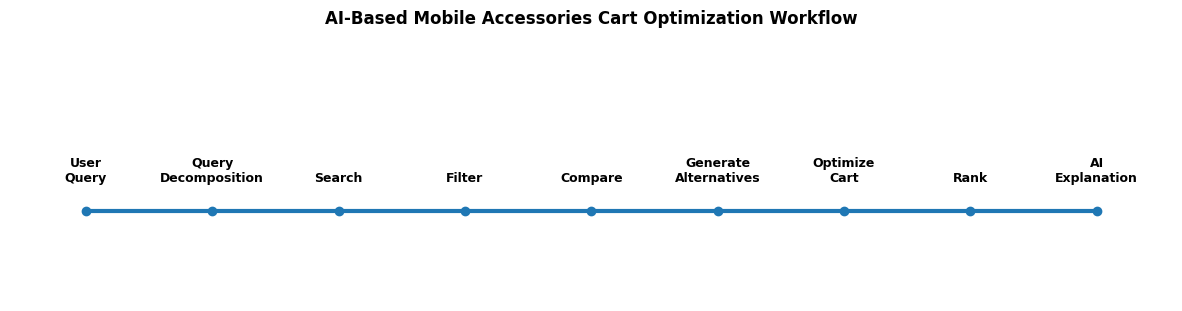

In [ ]:
steps = ["User Query", "Query Decomposition", "Search", "Filter", "Compare",
         "Generate Alternatives", "Optimize Cart", "Rank", "AI Explanation"]

fig, ax = plt.subplots(figsize=(15, 3.5))

x = list(range(len(steps)))
ax.plot(x, [0] * len(steps), marker="o", linewidth=3)

for xi, step in zip(x, steps):
    ax.text(xi, 0.12, step.replace(" ", "\n"), ha="center", va="bottom",
            fontsize=9, fontweight="bold")

ax.set_xlim(-0.6, len(steps) - 0.4)
ax.set_ylim(-0.4, 0.8)
ax.axis("off")
ax.set_title("AI-Based Mobile Accessories Cart Optimization Workflow",
             fontsize=12, fontweight="bold")

plt.show()

## 11. Visualizations

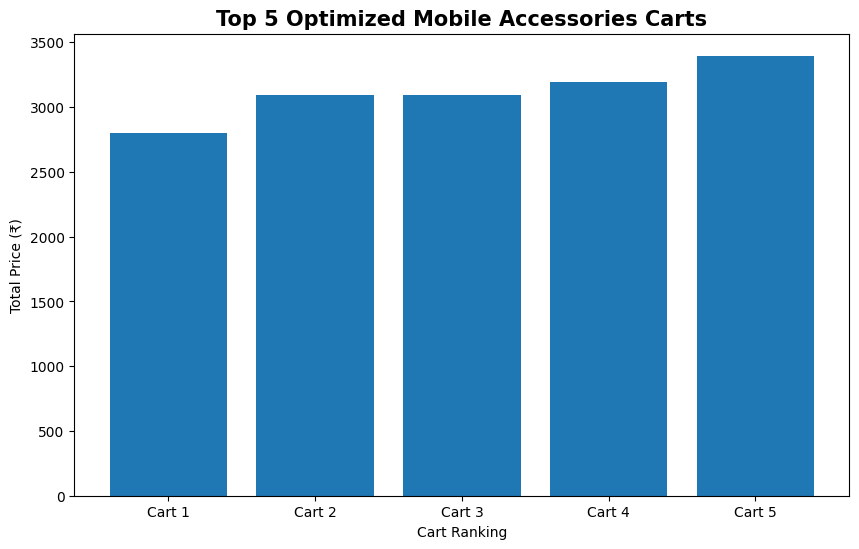

In [ ]:
if len(carts) > 0:

    top_carts = carts.head(5).copy()

    labels = [f"Cart {i + 1}" for i in range(len(top_carts))]

    plt.figure(figsize=(10, 6))

    plt.bar(labels, top_carts["total_price"])

    plt.title("Top 5 Optimized Mobile Accessories Carts",
              fontsize=15, fontweight="bold")

    plt.xlabel("Cart Ranking")
    plt.ylabel("Total Price (₹)")

    plt.show()

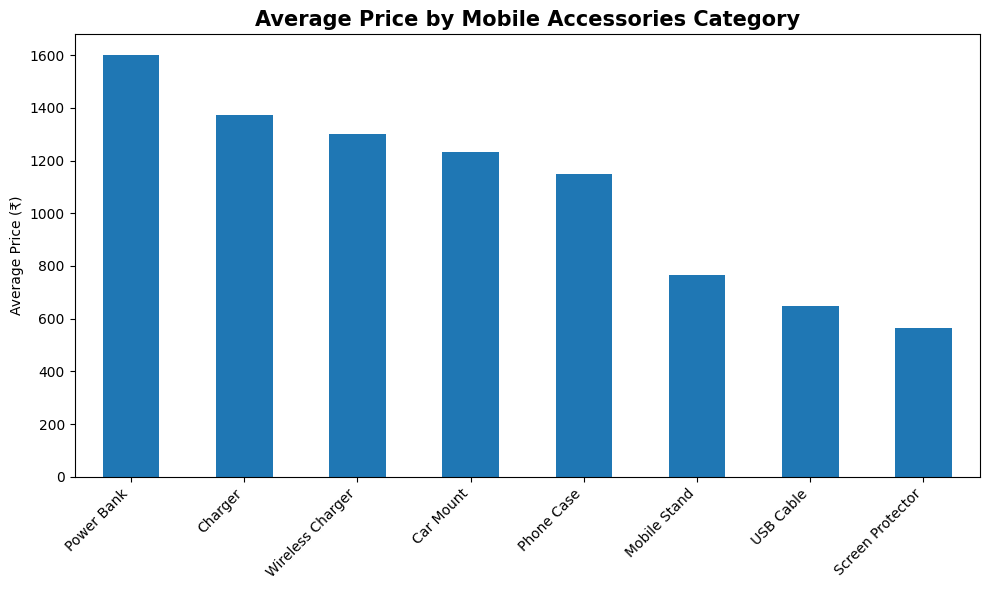

In [ ]:
avg_price = df.groupby("category")["price"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

avg_price.plot(kind="bar")

plt.title("Average Price by Mobile Accessories Category",
          fontsize=15, fontweight="bold")

plt.xlabel("")
plt.ylabel("Average Price (₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

## Conclusion

The experiment successfully demonstrated an AI-based e-commerce cart optimization system that understands user requirements, filters suitable products, compares their price and ratings, and selects an optimized cart within the given budget. It shows how AI and optimization techniques can help provide cost-effective and quality-based product recommendations.